In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [2]:
# df = pd.read_excel("online_retail_II.xlsx")
df = pd.read_excel("online_retail_II.xlsx")

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      525461 non-null  object        
 1   StockCode    525461 non-null  object        
 2   Description  522533 non-null  object        
 3   Quantity     525461 non-null  int64         
 4   InvoiceDate  525461 non-null  datetime64[ns]
 5   Price        525461 non-null  float64       
 6   Customer ID  417534 non-null  float64       
 7   Country      525461 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 32.1+ MB


In [4]:
df.describe()

,Quantity,InvoiceDate,Price,Customer ID
count,525461.000000,525461,525461.000000,417534.000000
mean,10.337667,2010-06-28 11:37:36.845017856,4.688834,15360.645478
min,-9600.000000,2009-12-01 07:45:00,-53594.360000,12346.000000
25%,1.000000,2010-03-21 12:20:00,1.250000,13983.000000
50%,3.000000,2010-07-06 09:51:00,2.100000,15311.000000
75%,10.000000,2010-10-15 12:45:00,4.210000,16799.000000
max,19152.000000,2010-12-09 20:01:00,25111.090000,18287.000000
std,107.424110,NaN,146.126914,1680.811316


In [5]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [6]:
init_shape=df.shape
init_shape

(525461, 8)

In [7]:
print('='*16,'Before Cleaning','='*16)
print(f'Total rows:              {len(df):,}')
print(f'Null values:             {df.isnull().sum().sum():,}')
print(f'  └─ Customer ID nulls:  {df["Customer ID"].isnull().sum():,}  (likely guest/anon buyers)')
print(f'  └─ Description nulls:  {df["Description"].isnull().sum():,}')
print(f'Duplicates:              {df.duplicated().sum():,}')
print(f'Negative Quantity rows:  {(df["Quantity"] < 0).sum():,}  (returns/cancellations)')
print(f'Zero/Negative Price:     {(df["Price"] <= 0).sum():,}')

================ Before Cleaning ================
Total rows:              525,461
Null values:             110,855
  └─ Customer ID nulls:  107,927  (likely guest/anon buyers)
  └─ Description nulls:  2,928
Duplicates:              6,865
Negative Quantity rows:  12,326  (returns/cancellations)
Zero/Negative Price:     3,690


In [8]:
df.dropna(subset=['Price', 'Quantity', 'InvoiceDate', 'StockCode'], inplace=True)
df = df[df['Price'] > 0]
df = df[df['Quantity'] > 0]
df.drop_duplicates(inplace=True)

print('='*16,'After Cleaning','='*16)
print(f'Rows removed: {init_shape[0] - len(df):,}')
print(f'Remaining:    {len(df):,}')

================ After Cleaning ================
Rows removed: 20,730
Remaining:    504,731


In [9]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['date']  = df['InvoiceDate'].dt.normalize()   # keep as Timestamp, not date object
df['year']  = df['InvoiceDate'].dt.year
df['month'] = df['InvoiceDate'].dt.month
df['week']  = df['InvoiceDate'].dt.isocalendar().week.astype(int)
df['dow']   = df['InvoiceDate'].dt.dayofweek
df['dow_name'] = df['InvoiceDate'].dt.day_name()

df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,date,year,month,week,dow,dow_name
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,2009-12-01,2009,12,49,1,Tuesday
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009-12-01,2009,12,49,1,Tuesday
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009-12-01,2009,12,49,1,Tuesday
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,2009-12-01,2009,12,49,1,Tuesday
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,2009-12-01,2009,12,49,1,Tuesday


In [10]:
df['revenue'] = df['Price'] * df['Quantity']

In [11]:
# B2B flag (large single-line orders at low unit price)
df['is_bulk'] = (df['Quantity'] >= 12) & (df['Price'] < df['Price'].median())

In [12]:
print('Year distribution:')
print(df['year'].value_counts())
print(f'\nDate range: {df["date"].min().date()} to {df["date"].max().date()}')

Year distribution:
year
2010    461278
2009     43453
Name: count, dtype: int64

Date range: 2009-12-01 to 2010-12-09


In [13]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,date,year,month,week,dow,dow_name,revenue,is_bulk
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,2009-12-01,2009,12,49,1,Tuesday,83.4,False
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009-12-01,2009,12,49,1,Tuesday,81.0,False
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009-12-01,2009,12,49,1,Tuesday,81.0,False
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,2009-12-01,2009,12,49,1,Tuesday,100.8,False
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,2009-12-01,2009,12,49,1,Tuesday,30.0,True


In [14]:
grouped_df = df.groupby(['date', 'StockCode']).agg(
    price   = ('Price',    'mean'),
    demand  = ('Quantity', 'sum'),
    revenue = ('revenue',  'sum'),
    n_txn   = ('Price',    'count'),       # number of invoices for this SKU on this day
).reset_index()

In [15]:
grouped_df.head(10)

,date,StockCode,price,demand,revenue,n_txn
0,2009-12-01,10002,0.850,12,10.20,1
1,2009-12-01,10120,0.210,60,12.60,1
2,2009-12-01,10125,1.275,5,5.10,2
3,2009-12-01,10133,0.850,6,5.10,1
4,2009-12-01,10135,1.250,17,21.25,3
5,2009-12-01,11001,3.430,2,6.86,1
6,2009-12-01,15034,0.485,3,1.11,2
7,2009-12-01,15036,0.650,55,35.75,2
8,2009-12-01,16047,0.850,1,0.85,1
9,2009-12-01,16225,1.250,4,5.00,1


In [16]:
grouped_df.tail()

,date,StockCode,price,demand,revenue,n_txn
266430,2010-12-09,C2,50.000000,2,100.00,2
266431,2010-12-09,DCGS0076,16.130000,1,16.13,1
266432,2010-12-09,DOT,592.534000,5,2962.67,5
266433,2010-12-09,M,15.000000,1,15.00,1
266434,2010-12-09,POST,19.111111,26,478.00,9


In [17]:
sc = grouped_df['StockCode'].astype(str)
grouped_df = grouped_df[sc.str.len() > 3]
grouped_df = grouped_df[sc.str.match(r'^\d')]
grouped_df = grouped_df.reset_index(drop=True)

In [18]:
print(f'Grouped shape: {grouped_df.shape}')
print(f'Unique SKUs:   {grouped_df["StockCode"].nunique():,}')
grouped_df.tail()

Grouped shape: (265475, 6)
Unique SKUs:   4,213


,date,StockCode,price,demand,revenue,n_txn
265470,2010-12-09,90200A,4.24,1,4.24,1
265471,2010-12-09,90200D,4.24,1,4.24,1
265472,2010-12-09,90210B,2.96,1,2.96,1
265473,2010-12-09,90211B,5.95,2,11.90,1
265474,2010-12-09,90214O,0.85,1,0.85,1


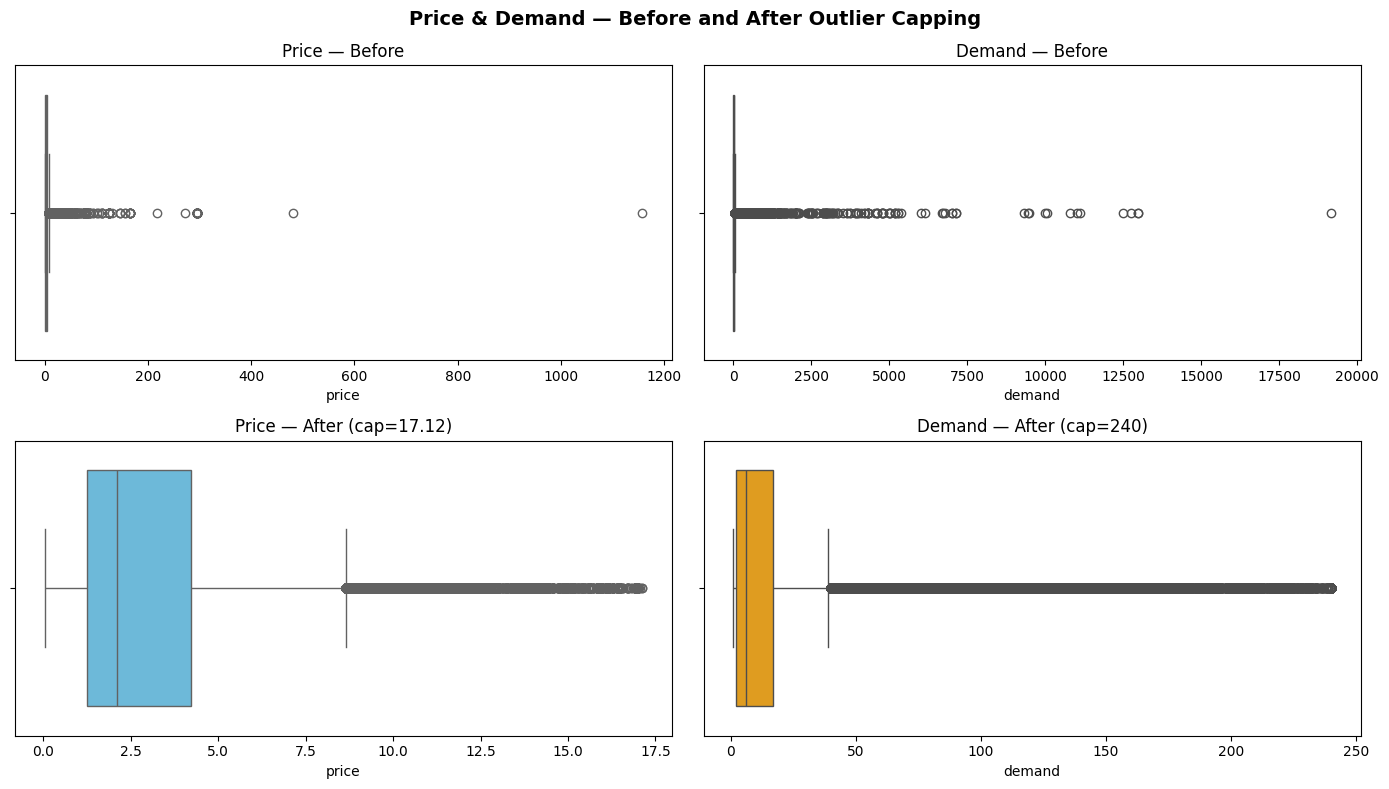


Rows after outlier removal: 260,286


In [19]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
fig.suptitle('Price & Demand — Before and After Outlier Capping', fontsize=14, fontweight='bold')

axes[0, 0].set_title('Price — Before')
sns.boxplot(x=grouped_df['price'], ax=axes[0, 0], color='#5bc0eb')

axes[0, 1].set_title('Demand — Before')
sns.boxplot(x=grouped_df['demand'], ax=axes[0, 1], color='#ffa500')

# Cap at 99th percentile
p99_price  = grouped_df['price'].quantile(0.99)
p99_demand = grouped_df['demand'].quantile(0.99)

grouped_df = grouped_df[
    (grouped_df['price']  <= p99_price) &
    (grouped_df['demand'] <= p99_demand)
].copy()

axes[1, 0].set_title(f'Price — After (cap={p99_price:.2f})')
sns.boxplot(x=grouped_df['price'], ax=axes[1, 0], color='#5bc0eb')

axes[1, 1].set_title(f'Demand — After (cap={p99_demand:.0f})')
sns.boxplot(x=grouped_df['demand'], ax=axes[1, 1], color='#ffa500')

plt.tight_layout()
plt.show()

print(f'\nRows after outlier removal: {len(grouped_df):,}')

In [20]:
print(f'Rows after outlier removal: {len(grouped_df):,}')

Rows after outlier removal: 260,286


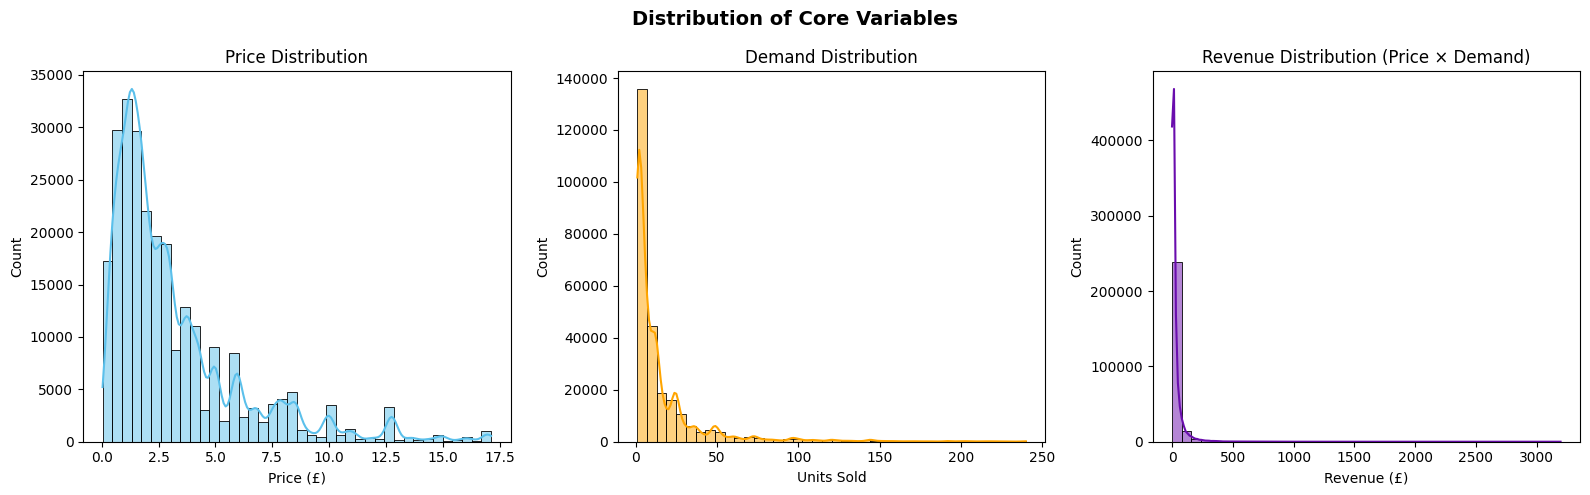

           price     demand    revenue
count  260286.00  260286.00  260286.00
mean        3.23      16.13      31.60
std         2.97      27.79      64.31
min         0.04       1.00       0.06
5%          0.42       1.00       1.66
25%         1.25       2.00       5.85
50%         2.10       6.00      15.00
75%         4.21      17.00      30.96
95%         9.95      65.00     116.32
99%        14.43     147.00     288.91
max        17.12     240.00    3196.11


In [21]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Distribution of Core Variables', fontsize=14, fontweight='bold')

sns.histplot(grouped_df['price'], bins=40, kde=True, ax=axes[0], color='#5bc0eb')
axes[0].set_title('Price Distribution')
axes[0].set_xlabel('Price (£)')

sns.histplot(grouped_df['demand'], bins=40, kde=True, ax=axes[1], color='#ffa500')
axes[1].set_title('Demand Distribution')
axes[1].set_xlabel('Units Sold')

sns.histplot(grouped_df['revenue'], bins=40, kde=True, ax=axes[2], color='#6a0dad')
axes[2].set_title('Revenue Distribution (Price × Demand)')
axes[2].set_xlabel('Revenue (£)')

plt.tight_layout()
plt.show()

print(grouped_df[['price', 'demand', 'revenue']].describe(percentiles=[.05, .25, .5, .75, .95, .99]).round(2))

In [22]:
from scipy import stats

MIN_OBS = 15   # minimum daily observations to compute elasticity
elasticity_records = []
for sku, grp in grouped_df.groupby('StockCode'):
    grp = grp.dropna(subset=['price', 'demand'])

    if len(grp) < MIN_OBS or grp['price'].std() < 0.01:
        continue
    x = np.log1p(grp['price'].values)
    y = np.log1p(grp['demand'].values)
    slope, intercept, r_val, p_val, _ = stats.linregress(x, y)
    elasticity_records.append({
        'StockCode':   sku,
        'elasticity':  slope,
        'r_squared':   r_val ** 2,
        'p_value':     p_val,
        'n_obs':       len(grp),
        'mean_price':  grp['price'].mean(),
        'mean_demand': grp['demand'].mean(),
        'total_revenue': grp['revenue'].sum(),
    })

elas_df = pd.DataFrame(elasticity_records)

# Keep statistically significant results (p < 0.05)
elas_sig = elas_df[elas_df['p_value'] < 0.05].copy()

print(f'SKUs with enough data to compute elasticity: {len(elas_df):,}')
print(f'Statistically significant (p<0.05):          {len(elas_sig):,}')
print(f'\nElasticity summary:')
print(elas_sig['elasticity'].describe(percentiles=[.1, .25, .5, .75, .9]).round(3))

SKUs with enough data to compute elasticity: 2,886
Statistically significant (p<0.05):          2,191

Elasticity summary:
count    2191.000
mean       -3.337
std         5.832
min       -81.810
10%        -6.043
25%        -3.136
50%        -2.145
75%        -1.468
90%        -1.046
max        86.165
Name: elasticity, dtype: float64


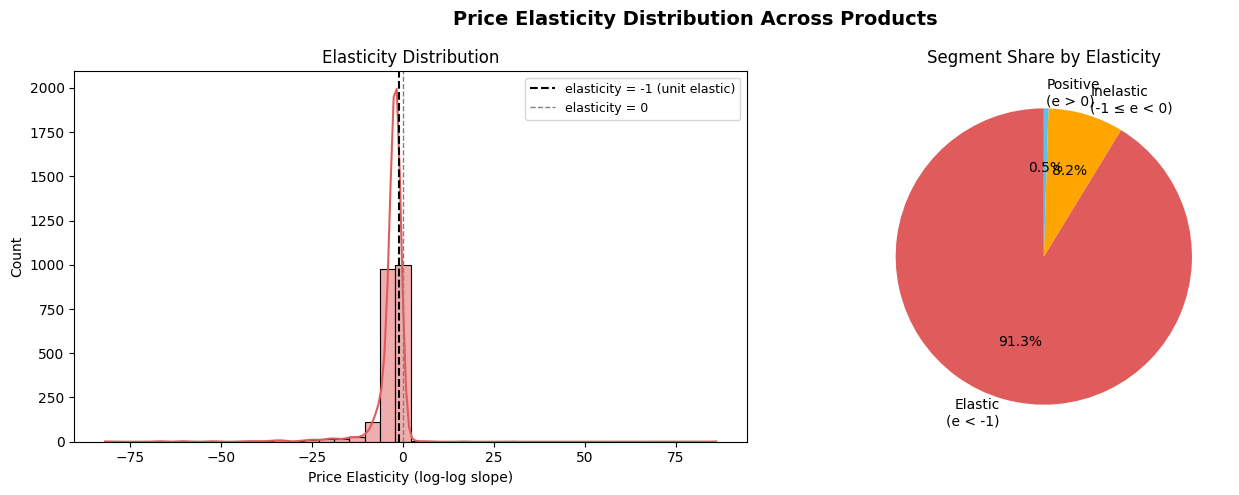

Elastic products (e < -1):      2,000  → price-sensitive, reduce price to gain revenue
Inelastic products (-1 ≤ e < 0): 180  → can raise price with low demand loss
Positive elasticity (e > 0):    11  → Giffen/luxury or data noise


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Price Elasticity Distribution Across Products', fontsize=14, fontweight='bold')

# Distribution of elasticity
sns.histplot(elas_sig['elasticity'], bins=40, kde=True, ax=axes[0], color='#e05c5c')
axes[0].axvline(-1, color='black', linestyle='--', lw=1.5, label='elasticity = -1 (unit elastic)')
axes[0].axvline(0,  color='gray',  linestyle='--', lw=1.0, label='elasticity = 0')
axes[0].set_title('Elasticity Distribution')
axes[0].set_xlabel('Price Elasticity (log-log slope)')
axes[0].legend(fontsize=9)

n_elastic   = (elas_sig['elasticity'] < -1).sum()
n_inelastic = (elas_sig['elasticity'].between(-1, 0)).sum()
n_positive  = (elas_sig['elasticity'] > 0).sum()

labels = ['Elastic\n(e < -1)', 'Inelastic\n(-1 ≤ e < 0)', 'Positive\n(e > 0)']
sizes  = [n_elastic, n_inelastic, n_positive]
colors = ['#e05c5c', '#ffa500', '#5bc0eb']
axes[1].pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90,
            textprops={'fontsize': 10})
axes[1].set_title('Segment Share by Elasticity')

plt.tight_layout()
plt.show()

print(f'Elastic products (e < -1):      {n_elastic:,}  → price-sensitive, reduce price to gain revenue')
print(f'Inelastic products (-1 ≤ e < 0): {n_inelastic:,}  → can raise price with low demand loss')
print(f'Positive elasticity (e > 0):    {n_positive:,}  → Giffen/luxury or data noise')

In [24]:
# Top 10 most elastic products (most price-sensitive)
print('=== Top 10 Most Elastic Products (price-sensitive) ===')
top_elastic = (
    elas_sig[elas_sig['elasticity'] < 0]
    .sort_values('elasticity')
    .head(10)[['StockCode', 'elasticity', 'r_squared', 'n_obs', 'mean_price', 'total_revenue']]
)
top_elastic.round(3)

=== Top 10 Most Elastic Products (price-sensitive) ===


,StockCode,elasticity,r_squared,n_obs,mean_price,total_revenue
642,21584,-81.810,0.083,138,1.649,3747.85
647,21590,-67.139,0.136,168,1.248,3834.75
2233,17164D,-65.950,0.199,21,0.418,218.34
1820,47422,-60.522,0.529,21,0.409,212.58
2232,17164B,-60.344,0.175,59,0.417,529.50
31,17021,-52.826,0.212,26,0.298,197.70
1819,47421,-51.864,0.436,18,0.410,189.78
1578,22709,-44.419,0.647,29,0.414,571.08
1638,22779,-42.053,0.511,30,4.230,1859.79
2800,90059A,-41.847,0.251,22,1.690,85.83


In [25]:
# Top 10 most inelastic (safest to raise price)
print('='*16,'Top 10 Most Inelastic Products (raise price safely)','='*16)
top_inelastic = (
    elas_sig[(elas_sig['elasticity'] >= -1) & (elas_sig['elasticity'] < 0)]
    .sort_values('elasticity', ascending=False)
    .head(10)[['StockCode', 'elasticity', 'r_squared', 'n_obs', 'mean_price', 'total_revenue']]
)
top_inelastic.round(3)

================ Top 10 Most Inelastic Products (raise price safely) ================


,StockCode,elasticity,r_squared,n_obs,mean_price,total_revenue
2722,85159A,-0.358,0.125,32,11.959,478.33
2723,85159B,-0.373,0.182,27,10.725,369.00
2725,85160B,-0.389,0.287,15,4.430,196.70
309,21115,-0.449,0.029,183,7.815,4884.14
423,21269,-0.466,0.162,47,9.763,798.84
2302,47021G,-0.474,0.118,41,2.463,240.22
2695,85121C,-0.484,0.089,45,9.729,884.21
787,21777,-0.488,0.019,200,8.976,9058.16
1047,22130,-0.529,0.069,129,1.802,4987.35
304,21109,-0.530,0.055,89,7.777,1787.75


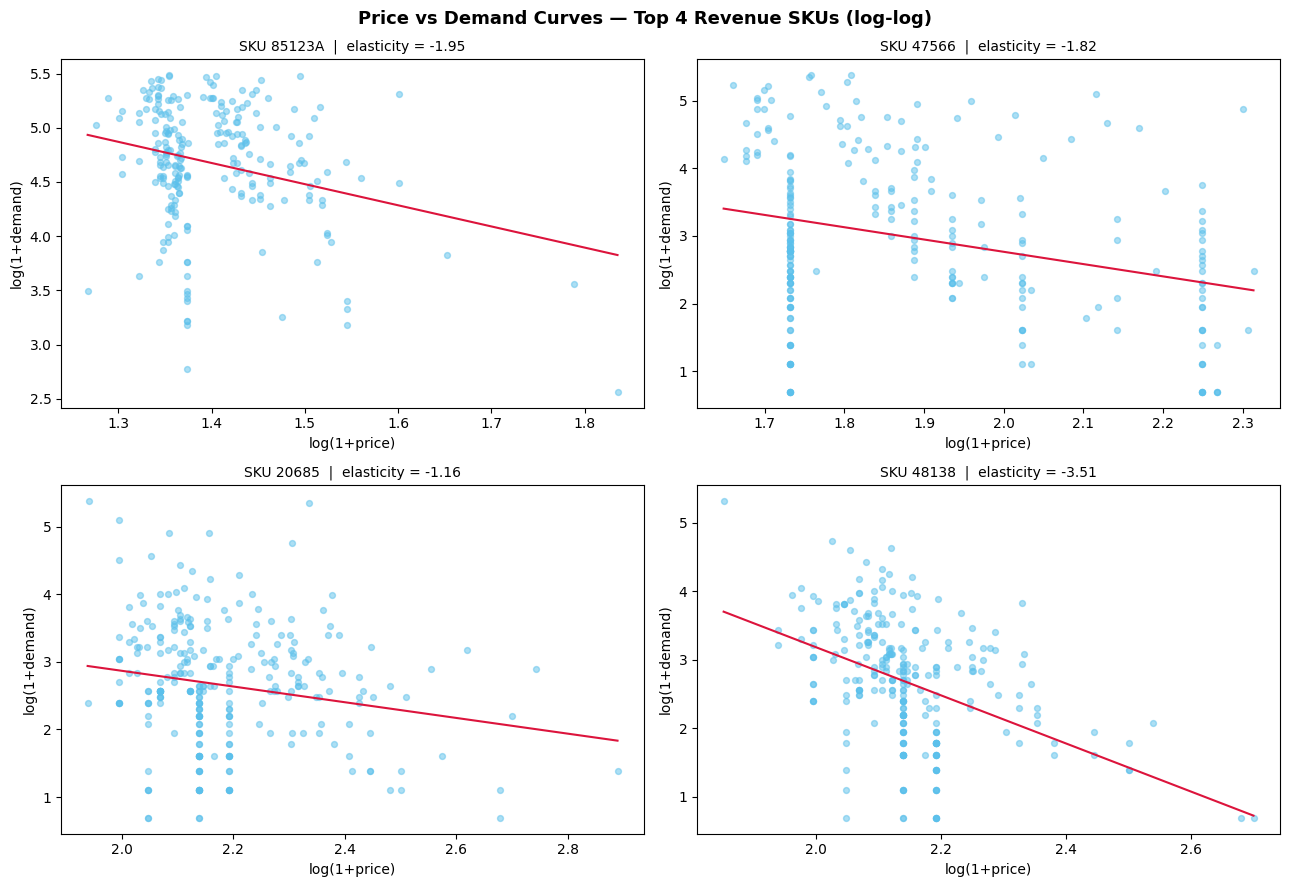

In [26]:
# Per-product demand curve — top 4 SKUs by revenue with significant elasticity
top_skus = (
    elas_sig[elas_sig['elasticity'] < 0]
    .sort_values('total_revenue', ascending=False)
    .head(4)['StockCode'].tolist()
)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle('Price vs Demand Curves — Top 4 Revenue SKUs (log-log)', fontsize=13, fontweight='bold')

for ax, sku in zip(axes.flat, top_skus):
    grp = grouped_df[grouped_df['StockCode'] == sku]
    x = np.log1p(grp['price'])
    y = np.log1p(grp['demand'])
    e = elas_sig[elas_sig['StockCode'] == sku]['elasticity'].values[0]

    ax.scatter(x, y, alpha=0.5, s=18, color='#5bc0eb')
    m, b = np.polyfit(x, y, 1)
    xline = np.linspace(x.min(), x.max(), 100)
    ax.plot(xline, m * xline + b, color='crimson', lw=1.5)
    ax.set_title(f'SKU {sku}  |  elasticity = {e:.2f}', fontsize=10)
    ax.set_xlabel('log(1+price)')
    ax.set_ylabel('log(1+demand)')

plt.tight_layout()
plt.show()

In [27]:
revenue_by_price = (
    grouped_df
    .assign(price_bin=lambda d: pd.qcut(d['price'], q=5, duplicates='drop'))
    .groupby(['StockCode', 'price_bin'], observed=True)
    .agg(avg_revenue=('revenue', 'mean'), n=('revenue', 'count'))
    .reset_index()
)

In [28]:
best_price_bin = (
    revenue_by_price
    .sort_values('avg_revenue', ascending=False)
    .groupby('StockCode')
    .first()
    .reset_index()[['StockCode', 'price_bin', 'avg_revenue', 'n']]
)

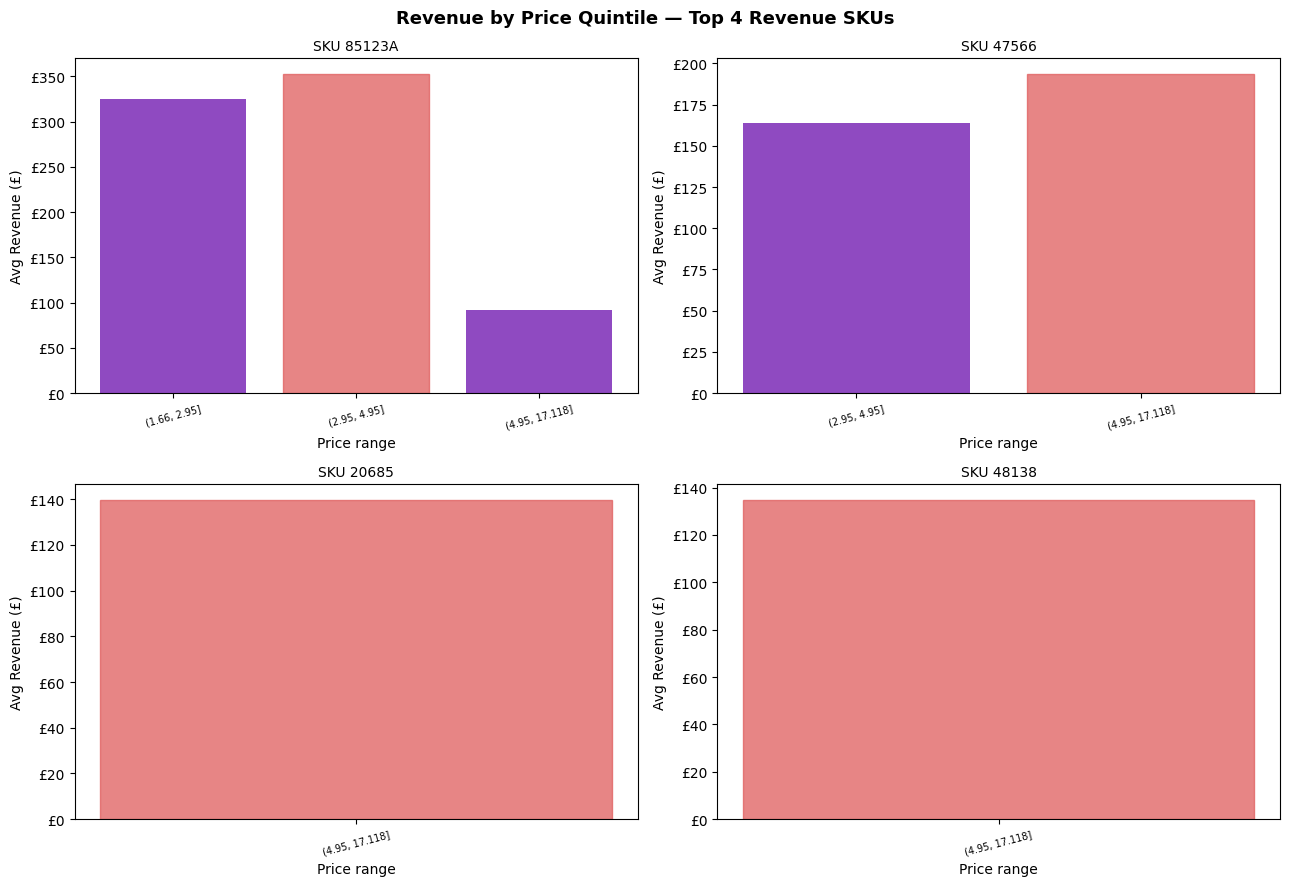

Red bar = price quintile with highest average revenue.


In [29]:
import matplotlib.ticker as mticker

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle('Revenue by Price Quintile — Top 4 Revenue SKUs', fontsize=13, fontweight='bold')

for ax, sku in zip(axes.flat, top_skus):
    grp = revenue_by_price[revenue_by_price['StockCode'] == sku]
    grp = grp.sort_values('price_bin')
    labels = [str(b) for b in grp['price_bin']]
    bars = ax.bar(range(len(grp)), grp['avg_revenue'], color='#6a0dad', alpha=0.75)
    best_idx = grp['avg_revenue'].idxmax()
    bars[grp.index.get_loc(best_idx)].set_color('#e05c5c')
    ax.set_xticks(range(len(grp)))
    ax.set_xticklabels(labels, rotation=15, fontsize=7)
    ax.set_title(f'SKU {sku}', fontsize=10)
    ax.set_xlabel('Price range')
    ax.set_ylabel('Avg Revenue (£)')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'£{v:,.0f}'))

plt.tight_layout()
plt.show()
print('Red bar = price quintile with highest average revenue.')

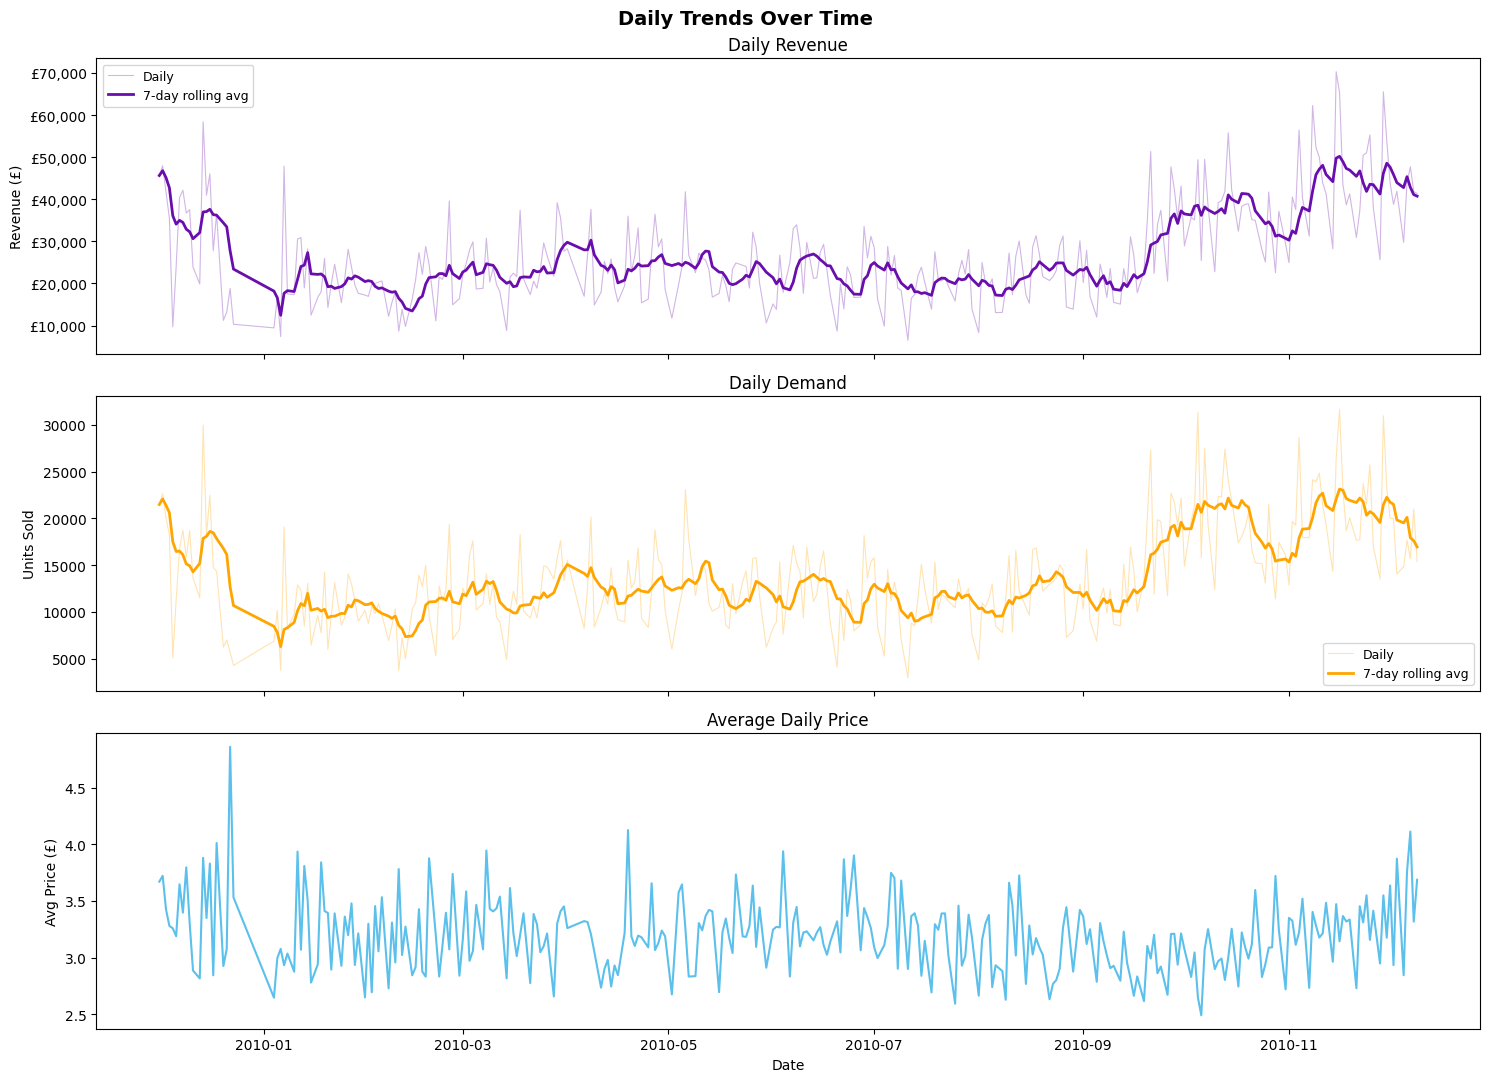

In [30]:
# Daily aggregates
daily = (
    grouped_df
    .groupby('date')
    .agg(total_revenue=('revenue', 'sum'),
         total_demand =('demand',  'sum'),
         avg_price    =('price',   'mean'),
         n_skus       =('StockCode','nunique'))
    .reset_index()
    .sort_values('date')
)
daily['revenue_7d'] = daily['total_revenue'].rolling(7, min_periods=1).mean()
daily['demand_7d']  = daily['total_demand'].rolling(7, min_periods=1).mean()

fig, axes = plt.subplots(3, 1, figsize=(15, 11), sharex=True)
fig.suptitle('Daily Trends Over Time', fontsize=14, fontweight='bold')

axes[0].plot(daily['date'], daily['total_revenue'], alpha=0.3, color='#6a0dad', lw=0.8, label='Daily')
axes[0].plot(daily['date'], daily['revenue_7d'],    color='#6a0dad', lw=2, label='7-day rolling avg')
axes[0].set_ylabel('Revenue (£)')
axes[0].set_title('Daily Revenue')
axes[0].legend(fontsize=9)
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'£{v:,.0f}'))

axes[1].plot(daily['date'], daily['total_demand'], alpha=0.3, color='#ffa500', lw=0.8, label='Daily')
axes[1].plot(daily['date'], daily['demand_7d'],    color='#ffa500', lw=2, label='7-day rolling avg')
axes[1].set_ylabel('Units Sold')
axes[1].set_title('Daily Demand')
axes[1].legend(fontsize=9)

axes[2].plot(daily['date'], daily['avg_price'], color='#5bc0eb', lw=1.5)
axes[2].set_ylabel('Avg Price (£)')
axes[2].set_title('Average Daily Price')
axes[2].set_xlabel('Date')

plt.tight_layout()
plt.show()

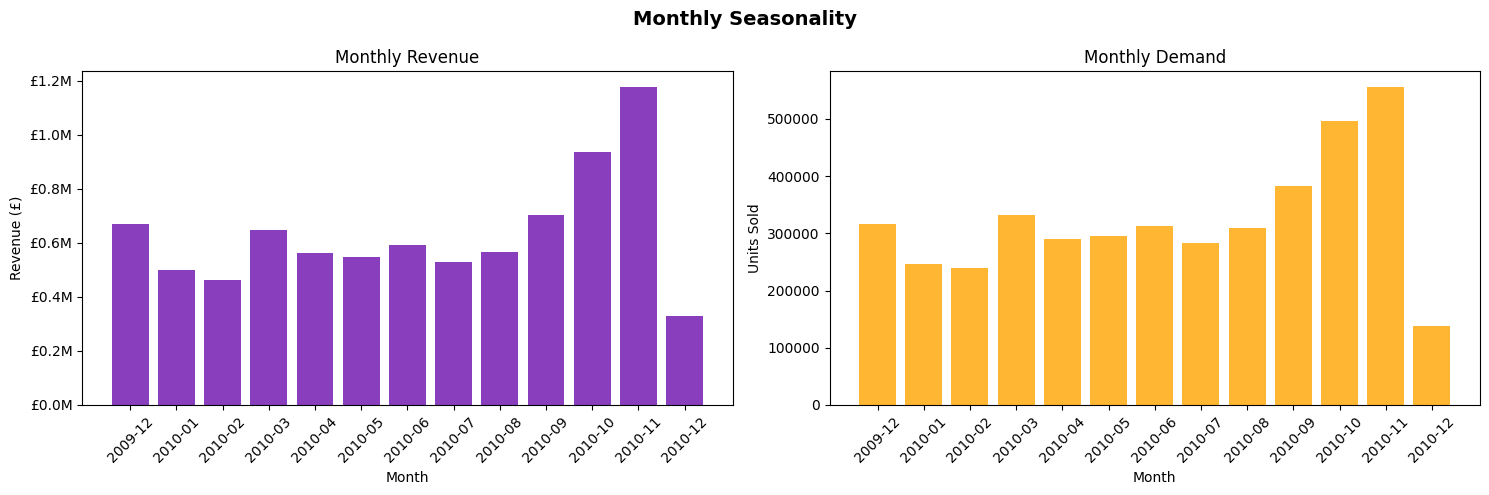

In [31]:
# Monthly revenue and demand
grouped_df['month_dt'] = pd.to_datetime(grouped_df['date']).dt.to_period('M')
monthly = (
    grouped_df
    .groupby('month_dt')
    .agg(revenue=('revenue','sum'), demand=('demand','sum'), avg_price=('price','mean'))
    .reset_index()
)
monthly['month_str'] = monthly['month_dt'].astype(str)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('Monthly Seasonality', fontsize=14, fontweight='bold')

axes[0].bar(monthly['month_str'], monthly['revenue'], color='#6a0dad', alpha=0.8)
axes[0].set_title('Monthly Revenue')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Revenue (£)')
axes[0].tick_params(axis='x', rotation=45)
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'£{v/1e6:.1f}M'))

axes[1].bar(monthly['month_str'], monthly['demand'], color='#ffa500', alpha=0.8)
axes[1].set_title('Monthly Demand')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Units Sold')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

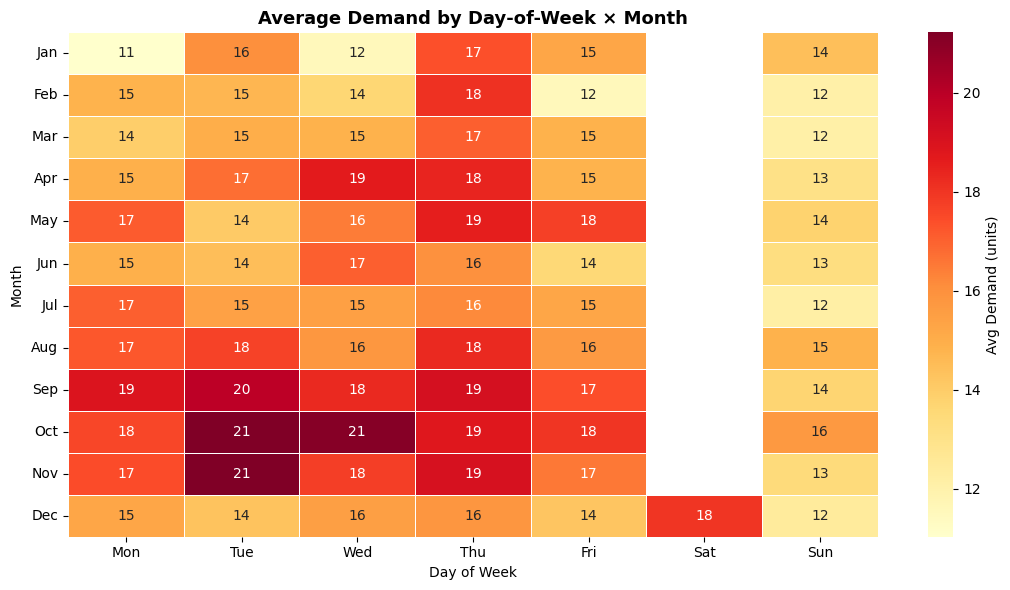

In [32]:
grouped_df['dow']   = pd.to_datetime(grouped_df['date']).dt.dayofweek
grouped_df['month'] = pd.to_datetime(grouped_df['date']).dt.month

dow_month = (
    grouped_df
    .groupby(['month', 'dow'])['demand']
    .mean()
    .unstack()
)
dow_month.columns = ['Mon','Tue','Wed','Thu','Fri','Sat','Sun']

fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(dow_month, annot=True, fmt='.0f', cmap='YlOrRd', ax=ax,
            linewidths=0.5, cbar_kws={'label': 'Avg Demand (units)'})
ax.set_title('Average Demand by Day-of-Week × Month', fontsize=13, fontweight='bold')
ax.set_xlabel('Day of Week')
ax.set_ylabel('Month')
ax.set_yticklabels(['Jan','Feb','Mar','Apr','May','Jun',
                    'Jul','Aug','Sep','Oct','Nov','Dec'], rotation=0)
plt.tight_layout()
plt.show()

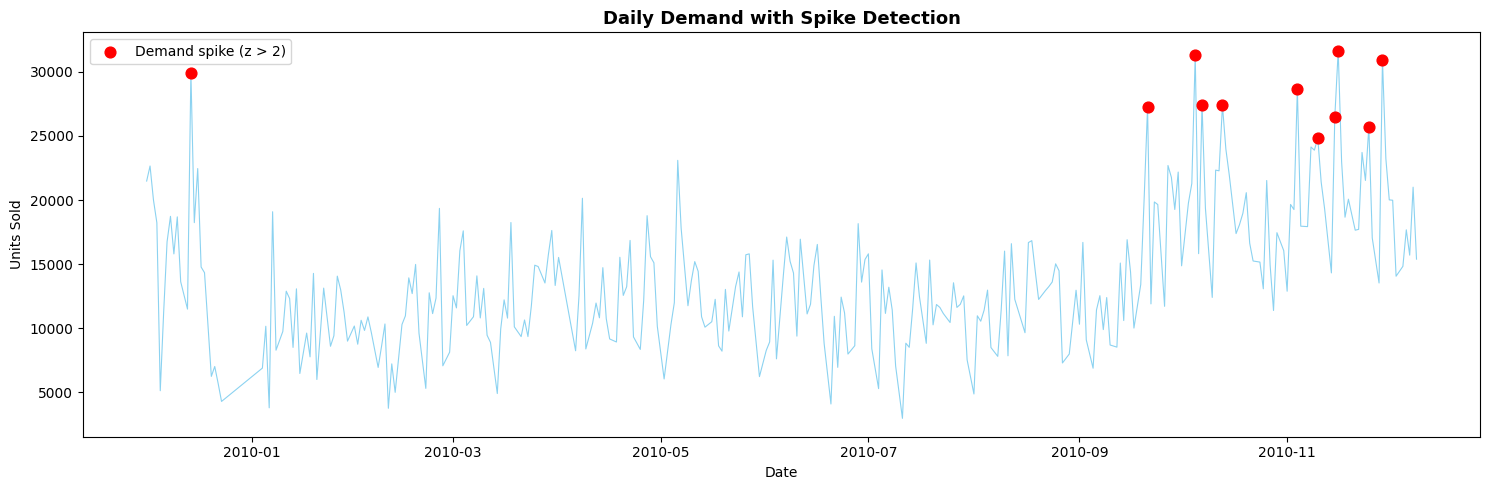

Demand spikes detected: 11
          date  total_demand  avg_price  z_score
286 2010-11-16         31656       3.14     3.39
250 2010-10-05         31313       2.65     3.32
297 2010-11-29         30962       3.55     3.26
12  2009-12-14         29950       3.88     3.07
276 2010-11-04         28664       3.22     2.82
252 2010-10-07         27449       3.07     2.59
257 2010-10-13         27385       2.80     2.58
238 2010-09-21         27266       2.99     2.56
285 2010-11-15         26480       3.47     2.41
294 2010-11-25         25713       3.16     2.27


In [33]:
daily['z_score'] = stats.zscore(daily['total_demand'])
spikes = daily[daily['z_score'] > 2].sort_values('z_score', ascending=False)

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(daily['date'], daily['total_demand'], color='#5bc0eb', lw=0.8, alpha=0.7)
ax.scatter(spikes['date'], spikes['total_demand'], color='red', s=60, zorder=5, label='Demand spike (z > 2)')
ax.set_title('Daily Demand with Spike Detection', fontsize=13, fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Units Sold')
ax.legend()
plt.tight_layout()
plt.show()

print(f'Demand spikes detected: {len(spikes)}')
print(spikes[['date', 'total_demand', 'avg_price', 'z_score']].head(10).round(2))

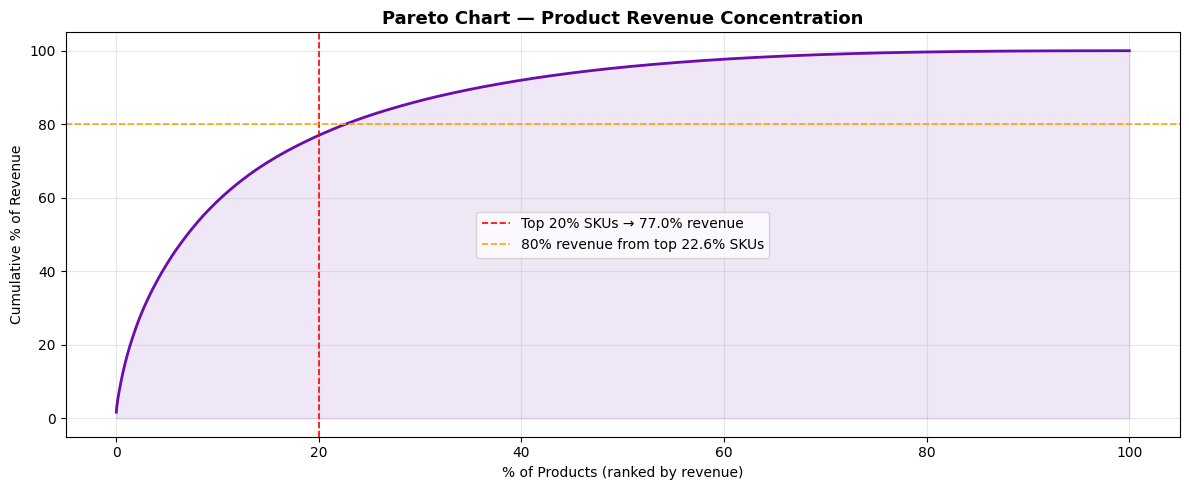

Top 20% of SKUs drive 77.0% of revenue
939 SKUs (22.6%) account for 80% of revenue

Top 10 SKUs by revenue:
StockCode   revenue
    22423 137946.80
   85123A  78775.38
    47566  45155.35
    21843  44524.17
   85099B  39911.59
    20685  39762.78
    48138  37296.97
    84879  35029.05
    20725  33847.35
    21621  32361.90


In [34]:
sku_revenue = (
    grouped_df
    .groupby('StockCode')['revenue']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)
sku_revenue['cumulative_pct'] = sku_revenue['revenue'].cumsum() / sku_revenue['revenue'].sum() * 100
sku_revenue['sku_pct'] = (np.arange(1, len(sku_revenue)+1) / len(sku_revenue)) * 100

top20_cutoff = sku_revenue[sku_revenue['sku_pct'] <= 20]['revenue'].sum() / sku_revenue['revenue'].sum() * 100
n_80_pct = (sku_revenue['cumulative_pct'] <= 80).sum()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(sku_revenue['sku_pct'], sku_revenue['cumulative_pct'], color='#6a0dad', lw=2)
ax.axvline(20, color='red', linestyle='--', lw=1.2, label=f'Top 20% SKUs → {top20_cutoff:.1f}% revenue')
ax.axhline(80, color='orange', linestyle='--', lw=1.2, label=f'80% revenue from top {n_80_pct/len(sku_revenue)*100:.1f}% SKUs')
ax.fill_between(sku_revenue['sku_pct'], sku_revenue['cumulative_pct'], alpha=0.1, color='#6a0dad')
ax.set_xlabel('% of Products (ranked by revenue)')
ax.set_ylabel('Cumulative % of Revenue')
ax.set_title('Pareto Chart — Product Revenue Concentration', fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f'Top 20% of SKUs drive {top20_cutoff:.1f}% of revenue')
print(f'{n_80_pct} SKUs ({n_80_pct/len(sku_revenue)*100:.1f}%) account for 80% of revenue')
print('\nTop 10 SKUs by revenue:')
print(sku_revenue.head(10)[['StockCode','revenue']].round(2).to_string(index=False))

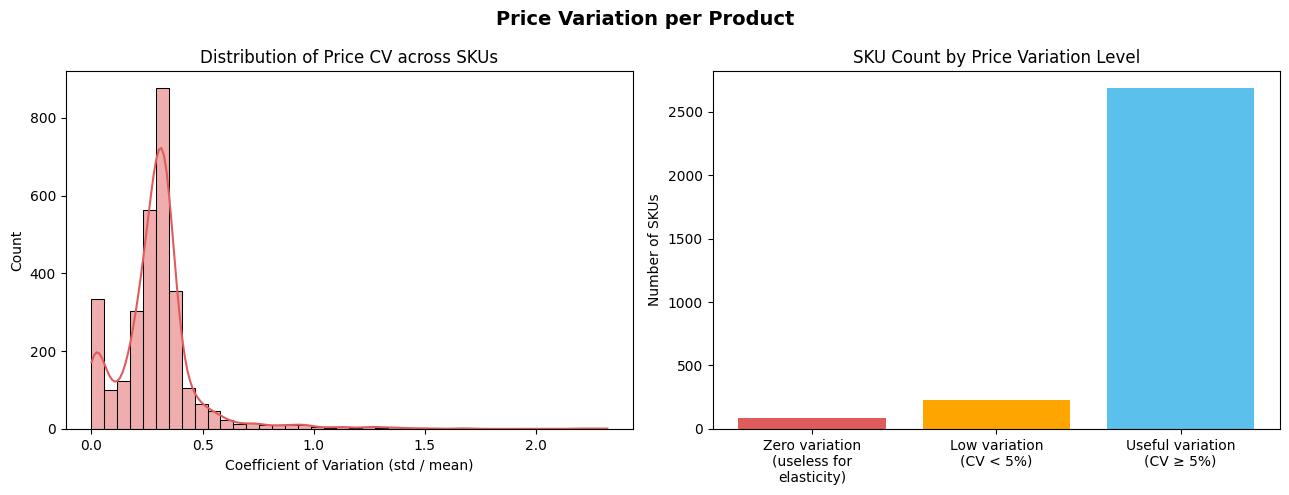

SKUs with zero price variation: 84 — cannot compute elasticity, skip for modeling
SKUs with useful variation:     2686


In [35]:
# Coefficient of Variation (CV) per SKU — how much does price actually vary?
price_var = (
    grouped_df
    .groupby('StockCode')['price']
    .agg(['mean', 'std', 'min', 'max', 'count'])
    .rename(columns={'count': 'n_obs'})
)
price_var['cv'] = price_var['std'] / price_var['mean']
price_var = price_var[price_var['n_obs'] >= MIN_OBS]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Price Variation per Product', fontsize=14, fontweight='bold')

sns.histplot(price_var['cv'].dropna(), bins=40, kde=True, ax=axes[0], color='#e05c5c')
axes[0].set_title('Distribution of Price CV across SKUs')
axes[0].set_xlabel('Coefficient of Variation (std / mean)')

zero_var = (price_var['std'] == 0).sum()
low_var  = (price_var['cv'] < 0.05).sum()
axes[1].bar(['Zero variation\n(useless for\nelasticity)',
             'Low variation\n(CV < 5%)',
             'Useful variation\n(CV ≥ 5%)'],
            [zero_var, low_var - zero_var, len(price_var) - low_var],
            color=['#e05c5c', '#ffa500', '#5bc0eb'])
axes[1].set_title('SKU Count by Price Variation Level')
axes[1].set_ylabel('Number of SKUs')

plt.tight_layout()
plt.show()

print(f'SKUs with zero price variation: {zero_var} — cannot compute elasticity, skip for modeling')
print(f'SKUs with useful variation:     {len(price_var) - low_var}')

Bulk purchase transactions: 20.1%


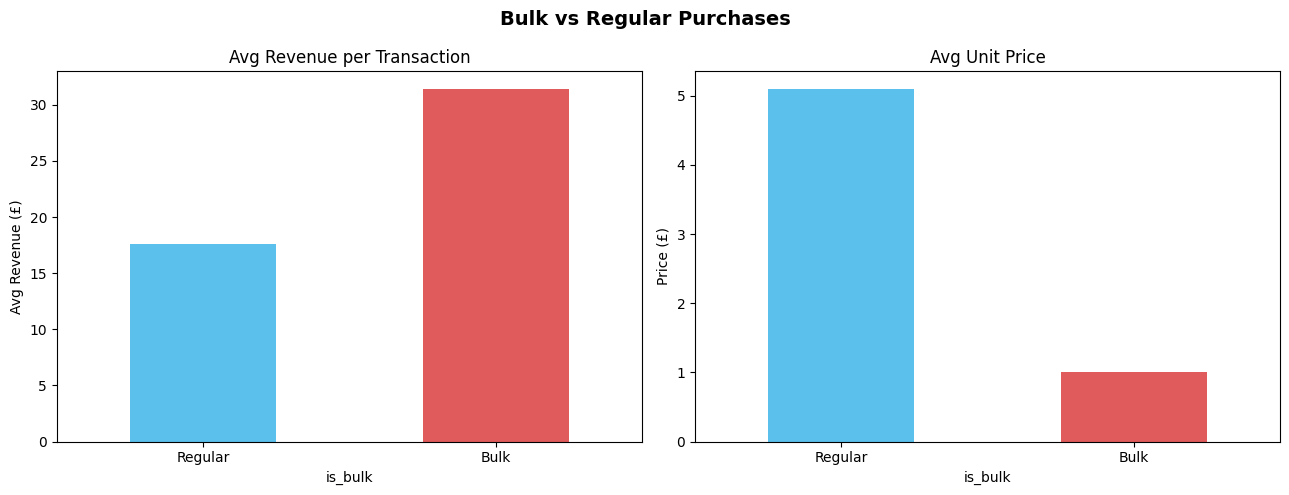


Country bulk purchase rate (top 10):
Country
Norway                  66.0%
Denmark                 59.6%
Sweden                  59.3%
Hong Kong               56.8%
Netherlands             53.3%
Canada                  53.2%
Poland                  52.7%
United Arab Emirates    51.4%
Japan                   48.2%
Austria                 46.2%
Name: is_bulk, dtype: object


In [36]:
bulk_share = df['is_bulk'].mean() * 100
print(f'Bulk purchase transactions: {bulk_share:.1f}%')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Bulk vs Regular Purchases', fontsize=14, fontweight='bold')

df.groupby('is_bulk')['revenue'].mean().plot(
    kind='bar', ax=axes[0], color=['#5bc0eb', '#e05c5c'], rot=0
)
axes[0].set_xticklabels(['Regular', 'Bulk'])
axes[0].set_title('Avg Revenue per Transaction')
axes[0].set_ylabel('Avg Revenue (£)')

df.groupby('is_bulk')['Price'].mean().plot(
    kind='bar', ax=axes[1], color=['#5bc0eb', '#e05c5c'], rot=0
)
axes[1].set_xticklabels(['Regular', 'Bulk'])
axes[1].set_title('Avg Unit Price')
axes[1].set_ylabel('Price (£)')

plt.tight_layout()
plt.show()

print('\nCountry bulk purchase rate (top 10):')
print(
    df.groupby('Country')['is_bulk']
    .mean()
    .sort_values(ascending=False)
    .head(10)
    .apply(lambda x: f'{x*100:.1f}%')
)

Lag feature preview for SKU 85123A:
            price  demand  revenue  price_lag1  demand_lag1  price_lag7  \
date                                                                      
2010-01-10   2.88      78   217.30        2.80        214.0        2.95   
2010-01-11   4.98      34   130.81        2.88         78.0        2.86   
2010-01-12   3.32     105   299.91        4.98         34.0        5.27   
2010-01-13   3.96      88   266.56        3.32        105.0        2.75   
2010-01-15   2.67     162   425.10        3.96         88.0        2.88   

            demand_lag7  price_lag14  demand_lag14  
date                                                
2010-01-10         24.0         2.92         179.0  
2010-01-11        115.0         2.68          96.0  
2010-01-12         12.0         2.83         172.0  
2010-01-13         37.0         2.83         231.0  
2010-01-15        162.0         3.46         239.0  


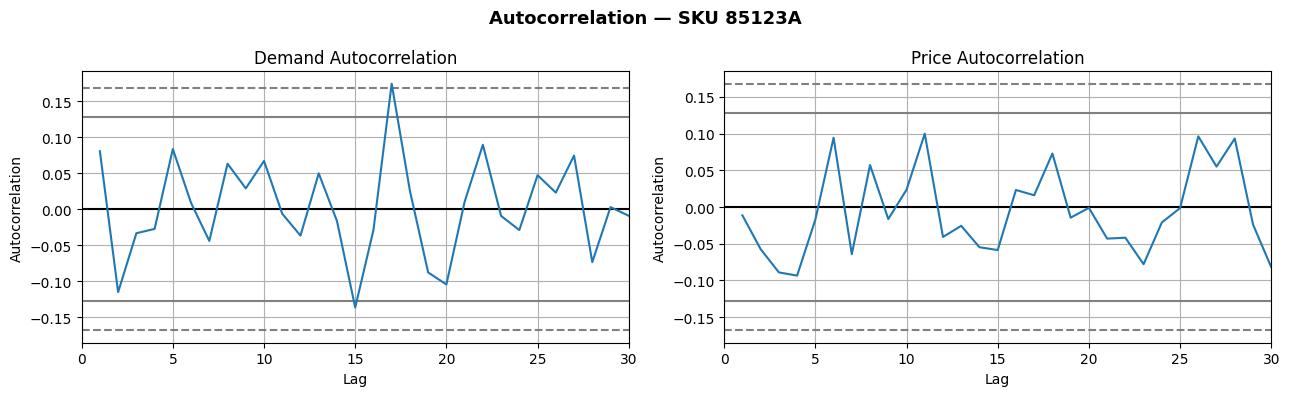

In [37]:
from pandas.plotting import autocorrelation_plot

# Example: lag features for a single high-revenue SKU
focus_sku = top_skus[0]
sku_ts = (
    grouped_df[grouped_df['StockCode'] == focus_sku]
    .sort_values('date')
    .set_index('date')
    [['price', 'demand', 'revenue']]
)

# Create lag features
for lag in [1, 7, 14]:
    sku_ts[f'price_lag{lag}']  = sku_ts['price'].shift(lag)
    sku_ts[f'demand_lag{lag}'] = sku_ts['demand'].shift(lag)

print(f'Lag feature preview for SKU {focus_sku}:')
print(sku_ts.dropna().head(5).round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle(f'Autocorrelation — SKU {focus_sku}', fontsize=13, fontweight='bold')
autocorrelation_plot(sku_ts['demand'].dropna(), ax=axes[0])
axes[0].set_title('Demand Autocorrelation')
axes[0].set_xlim(0, 30)
autocorrelation_plot(sku_ts['price'].dropna(), ax=axes[1])
axes[1].set_title('Price Autocorrelation')
axes[1].set_xlim(0, 30)
plt.tight_layout()
plt.show()

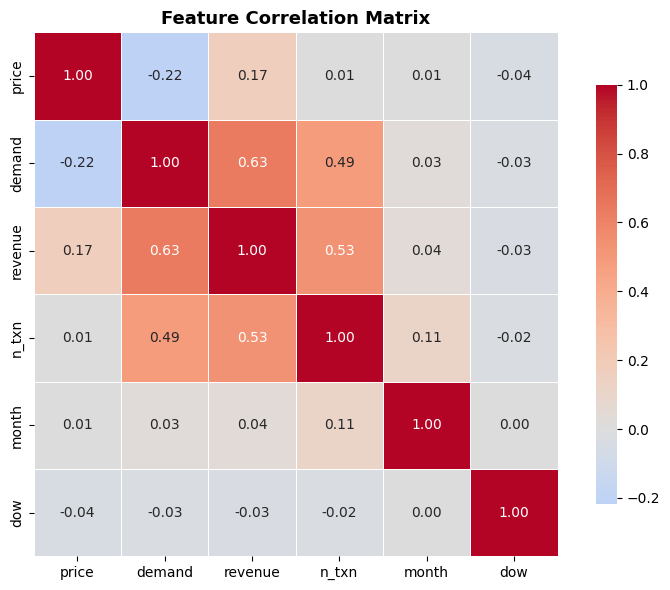

In [38]:
corr_df = grouped_df[['price', 'demand', 'revenue', 'n_txn', 'month', 'dow']].copy()
corr_matrix = corr_df.corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            ax=ax, linewidths=0.5, square=True,
            cbar_kws={'shrink': 0.8})
ax.set_title('Feature Correlation Matrix', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [39]:
# Sparse product filter: keep only SKUs with >= MIN_OBS observations
sku_counts = grouped_df['StockCode'].value_counts()
valid_skus  = sku_counts[sku_counts >= MIN_OBS].index
model_df    = grouped_df[grouped_df['StockCode'].isin(valid_skus)].copy()

# Attach elasticity label
elas_map = elas_sig.set_index('StockCode')['elasticity'].to_dict()
model_df['elasticity'] = model_df['StockCode'].map(elas_map)
model_df['price_sensitive'] = model_df['elasticity'] < -1

print('=== Modeling-Ready Dataset ===')
print(f'Rows:            {len(model_df):,}')
print(f'Unique SKUs:     {model_df["StockCode"].nunique():,}')
print(f'Date range:      {model_df["date"].min().date()} to {model_df["date"].max().date()}')
print(f'Price-sensitive: {model_df["StockCode"].isin(elas_sig[elas_sig["elasticity"]<-1]["StockCode"]).sum():,} rows')
print()
print('Columns:')
print(model_df.dtypes)

model_df.head()

=== Modeling-Ready Dataset ===
Rows:            253,009
Unique SKUs:     2,996
Date range:      2009-12-01 to 2010-12-09
Price-sensitive: 188,169 rows

Columns:
date               datetime64[ns]
StockCode                  object
price                     float64
demand                      int64
revenue                   float64
n_txn                       int64
month_dt                period[M]
dow                         int32
month                       int32
elasticity                float64
price_sensitive              bool
dtype: object


,date,StockCode,price,demand,revenue,n_txn,month_dt,dow,month,elasticity,price_sensitive
0,2009-12-01,10002,0.850,12,10.20,1,2009-12,1,12,-2.954460,True
1,2009-12-01,10120,0.210,60,12.60,1,2009-12,1,12,-7.934931,True
2,2009-12-01,10125,1.275,5,5.10,2,2009-12,1,12,-3.099670,True
3,2009-12-01,10133,0.850,6,5.10,1,2009-12,1,12,-3.345425,True
4,2009-12-01,10135,1.250,17,21.25,3,2009-12,1,12,-2.062264,True


In [40]:
# Save modeling-ready dataset
model_df.to_csv('dynamic_pricing_model_ready.csv', index=False)
elas_sig.to_csv('elasticity_by_sku.csv', index=False)
print('Saved:')
print('  dynamic_pricing_model_ready.csv  — grouped daily data with elasticity labels')
print('  elasticity_by_sku.csv            — elasticity per SKU with significance stats')

Saved:
  dynamic_pricing_model_ready.csv  — grouped daily data with elasticity labels
  elasticity_by_sku.csv            — elasticity per SKU with significance stats
